<a href="https://colab.research.google.com/github/Adediwuraola12/loan-prediction-project/blob/rachaelmusa/Copy_of_Loan_Prediction_Project_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# imported numpy,pandas,matplotlib and seaborn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from matplotlib.ticker import PercentFormatter
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier



In [ ]:
# used df to read and load the excel dataset and used df.head to print the first 5 rows
df = pd.read_excel("default of credit card clients.xls", header=1)
df.head()


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [ ]:
%pip install xlrd

Defaulting to user installation because normal site-packages is not writeable
     -------------------------------------- 96.6/96.6 kB 251.6 kB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


In [ ]:
# use to show the dimension of the data set i.e 30000 rows and 25 columns
df.shape

(30000, 25)

In [ ]:
#used to print the column heads so as to know them
df.columns

Index(['ID', 'LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0',
       'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2',
       'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1',
       'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6',
       'default payment next month'],
      dtype='object')

In [ ]:
#used to describe the data by showing the mean,standard deviation,count,minimum,maximum,50%,75% of the whole dataset
df.describe()

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
count,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,...,30000.000000,30000.000000,30000.000000,30000.000000,3.000000e+04,30000.00000,30000.000000,30000.000000,30000.000000,30000.000000
mean,15000.500000,167484.322667,1.603733,1.853133,1.551867,35.485500,-0.016700,-0.133767,-0.166200,-0.220667,...,43262.948967,40311.400967,38871.760400,5663.580500,5.921163e+03,5225.68150,4826.076867,4799.387633,5215.502567,0.221200
std,8660.398374,129747.661567,0.489129,0.790349,0.521970,9.217904,1.123802,1.197186,1.196868,1.169139,...,64332.856134,60797.155770,59554.107537,16563.280354,2.304087e+04,17606.96147,15666.159744,15278.305679,17777.465775,0.415062
min,1.000000,10000.000000,1.000000,0.000000,0.000000,21.000000,-2.000000,-2.000000,-2.000000,-2.000000,...,-170000.000000,-81334.000000,-339603.000000,0.000000,0.000000e+00,0.00000,0.000000,0.000000,0.000000,0.000000
25%,7500.750000,50000.000000,1.000000,1.000000,1.000000,28.000000,-1.000000,-1.000000,-1.000000,-1.000000,...,2326.750000,1763.000000,1256.000000,1000.000000,8.330000e+02,390.00000,296.000000,252.500000,117.750000,0.000000
50%,15000.500000,140000.000000,2.000000,2.000000,2.000000,34.000000,0.000000,0.000000,0.000000,0.000000,...,19052.000000,18104.500000,17071.000000,2100.000000,2.009000e+03,1800.00000,1500.000000,1500.000000,1500.000000,0.000000
75%,22500.250000,240000.000000,2.000000,2.000000,2.000000,41.000000,0.000000,0.000000,0.000000,0.000000,...,54506.000000,50190.500000,49198.250000,5006.000000,5.000000e+03,4505.00000,4013.250000,4031.500000,4000.000000,0.000000
max,30000.000000,1000000.000000,2.000000,6.000000,3.000000,79.000000,8.000000,8.000000,8.000000,8.000000,...,891586.000000,927171.000000,961664.000000,873552.000000,1.684259e+06,896040.00000,621000.000000,426529.000000,528666.000000,1.000000


In [ ]:
#to check for null or missing values
df.isnull().sum()

ID                            0
LIMIT_BAL                     0
SEX                           0
EDUCATION                     0
MARRIAGE                      0
AGE                           0
PAY_0                         0
PAY_2                         0
PAY_3                         0
PAY_4                         0
PAY_5                         0
PAY_6                         0
BILL_AMT1                     0
BILL_AMT2                     0
BILL_AMT3                     0
BILL_AMT4                     0
BILL_AMT5                     0
BILL_AMT6                     0
PAY_AMT1                      0
PAY_AMT2                      0
PAY_AMT3                      0
PAY_AMT4                      0
PAY_AMT5                      0
PAY_AMT6                      0
default payment next month    0
dtype: int64

Dataset Overview (df.info()) Contibuted by Rachael Omole Musa:
The df.info() output, summarizes the structure of the dataset used. It displays the number of rows, column names and data types.

In [ ]:
#to check for the dataset information. it  shows the data type of the dataset by column
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   ID                          30000 non-null  int64
 1   LIMIT_BAL                   30000 non-null  int64
 2   SEX                         30000 non-null  int64
 3   EDUCATION                   30000 non-null  int64
 4   MARRIAGE                    30000 non-null  int64
 5   AGE                         30000 non-null  int64
 6   PAY_0                       30000 non-null  int64
 7   PAY_2                       30000 non-null  int64
 8   PAY_3                       30000 non-null  int64
 9   PAY_4                       30000 non-null  int64
 10  PAY_5                       30000 non-null  int64
 11  PAY_6                       30000 non-null  int64
 12  BILL_AMT1                   30000 non-null  int64
 13  BILL_AMT2                   30000 non-null  int64
 14  BILL_A

In [ ]:
#to check for duplicated values
df.duplicated().sum()

0

In [ ]:
#used to rename the columns for better understanding
df.rename(columns ={
    "ID": "Customer_ID",
    "LIMIT_BAL": "Credit_Limit",
    "SEX": "Gender",
    "EDUCATION":"Education",
    "MARRIAGE": "Marital_Status",
    "AGE":"Age",
    "PAY_0":"REPAY_SEPTEMBER",
    "PAY_2":"REPAY_AUGUST",
    "PAY_3":"REPAY_JULY",
    "PAY_4":"REPAY_JUNE",
    "PAY_5":"REPAY_MAY",
    "PAY_6":"REPAY_APRIL",
    "BILL_AMT1":"BILL_SEPTEMBER",
    "BILL_AMT2":"BILL_AUGUST",
    "BILL_AMT3":"BILL_JULY",
    "BILL_AMT4":"BILL_JUNE",
    "BILL_AMT5":"BILL_MAY",
    "BILL_AMT6":"BILL_APRIL",
    "PAY_AMT1":"PAYMENT_SEPTEMBER",
    "PAY_AMT2":"PAYMENT_AUGUST",
    "PAY_AMT3":"PAYMENT_JULY",
    "PAY_AMT4":"PAYMENT_JUNE",
    "PAY_AMT5":"PAYMENT_MAY",
    "PAY_AMT6":"PAYMENT_APRIL",
    "default payment next month": "DEFAULT_NEXT_MONTH"

}, inplace=True)

In [ ]:
#to check and list the columns renamed
df.columns.tolist()

['Customer_ID',
 'Credit_Limit',
 'Gender',
 'Education',
 'Marital_Status',
 'Age',
 'REPAY_SEPTEMBER',
 'REPAY_AUGUST',
 'REPAY_JULY',
 'REPAY_JUNE',
 'REPAY_MAY',
 'REPAY_APRIL',
 'BILL_SEPTEMBER',
 'BILL_AUGUST',
 'BILL_JULY',
 'BILL_JUNE',
 'BILL_MAY',
 'BILL_APRIL',
 'PAYMENT_SEPTEMBER',
 'PAYMENT_AUGUST',
 'PAYMENT_JULY',
 'PAYMENT_JUNE',
 'PAYMENT_MAY',
 'PAYMENT_APRIL',
 'DEFAULT_NEXT_MONTH']

In [ ]:
df.head()

,Customer_ID,Credit_Limit,Gender,Education,Marital_Status,Age,REPAY_SEPTEMBER,REPAY_AUGUST,REPAY_JULY,REPAY_JUNE,...,BILL_JUNE,BILL_MAY,BILL_APRIL,PAYMENT_SEPTEMBER,PAYMENT_AUGUST,PAYMENT_JULY,PAYMENT_JUNE,PAYMENT_MAY,PAYMENT_APRIL,DEFAULT_NEXT_MONTH
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [ ]:
#to count the number of gender based on their category. 1=male, 2=female
df["Gender"].value_counts()

2    18112
1    11888
Name: Gender, dtype: int64

In [ ]:
#to verify the count of education based on  its categories
df["Education"].value_counts()

2    14030
1    10585
3     4917
5      280
4      123
6       51
0       14
Name: Education, dtype: int64

In [ ]:
#to verify the count of marital status based on categories
df["Marital_Status"].value_counts()

2    15964
1    13659
3      323
0       54
Name: Marital_Status, dtype: int64

In [ ]:
df["REPAY_SEPTEMBER"].value_counts().sort_index()

-2     2759
-1     5686
 0    14737
 1     3688
 2     2667
 3      322
 4       76
 5       26
 6       11
 7        9
 8       19
Name: REPAY_SEPTEMBER, dtype: int64

In [ ]:
#to check the categories (status codes) of the loan repayment by months
df[[
    "REPAY_SEPTEMBER",
    "REPAY_AUGUST",
    "REPAY_JULY",
    "REPAY_JUNE",
    "REPAY_MAY",
    "REPAY_APRIL"
]].apply(pd.Series.value_counts)

,REPAY_SEPTEMBER,REPAY_AUGUST,REPAY_JULY,REPAY_JUNE,REPAY_MAY,REPAY_APRIL
-2,2759,3782,4085,4348,4546.0,4895.0
-1,5686,6050,5938,5687,5539.0,5740.0
0,14737,15730,15764,16455,16947.0,16286.0
1,3688,28,4,2,NaN,NaN
2,2667,3927,3819,3159,2626.0,2766.0
3,322,326,240,180,178.0,184.0
4,76,99,76,69,84.0,49.0
5,26,25,21,35,17.0,13.0
6,11,12,23,5,4.0,19.0
7,9,20,27,58,58.0,46.0


In [ ]:
#to calculate the count of loan repayment by  default category
df["DEFAULT_NEXT_MONTH"].value_counts()

0    23364
1     6636
Name: DEFAULT_NEXT_MONTH, dtype: int64

In [ ]:
#to calculate the percentage of the laon repayment default
df["DEFAULT_NEXT_MONTH"].value_counts(normalize=True) * 100

0    77.88
1    22.12
Name: DEFAULT_NEXT_MONTH, dtype: float64

In [ ]:
#to check for unique values of categories and columns of the dataset i.e to check how many distinct values each column has
df.nunique()

Customer_ID           30000
Credit_Limit             81
Gender                    2
Education                 7
Marital_Status            4
Age                      56
REPAY_SEPTEMBER          11
REPAY_AUGUST             11
REPAY_JULY               11
REPAY_JUNE               11
REPAY_MAY                10
REPAY_APRIL              10
BILL_SEPTEMBER        22723
BILL_AUGUST           22346
BILL_JULY             22026
BILL_JUNE             21548
BILL_MAY              21010
BILL_APRIL            20604
PAYMENT_SEPTEMBER      7943
PAYMENT_AUGUST         7899
PAYMENT_JULY           7518
PAYMENT_JUNE           6937
PAYMENT_MAY            6897
PAYMENT_APRIL          6939
DEFAULT_NEXT_MONTH        2
dtype: int64

In [ ]:
df[df["Education"].isin([0, 5, 6])][["Education"]].value_counts()

Education
5            280
6             51
0             14
dtype: int64

In [ ]:
#To replace the unstated categories in education under others for easier analysis
df["Education"] = df["Education"].replace({
    0:4,
    5:4,
    6:4
})

In [ ]:
#To replace the unstated category in marital status to others
df["Marital_Status"] = df["Marital_Status"].replace({
    0:3
})

In [ ]:
#Did this to prevent deleting neccessary data and reducing the data set
print(df["Education"].value_counts().sort_index())
print(df["Marital_Status"].value_counts().sort_index())

1    10585
2    14030
3     4917
4      468
Name: Education, dtype: int64
1    13659
2    15964
3      377
Name: Marital_Status, dtype: int64


Gender
1    24.167227
2    20.776281
Name: DEFAULT_NEXT_MONTH, dtype: float64


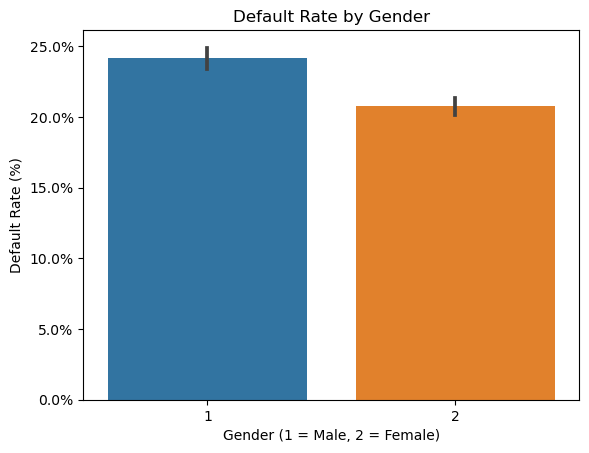

In [ ]:
#Starting EDA (Exploratory Data Analysis). Calculating default rate by gender and visualising it
gender_default = df.groupby("Gender")["DEFAULT_NEXT_MONTH"].mean() * 100
print(gender_default)

sns.barplot(x ="Gender",y="DEFAULT_NEXT_MONTH", data =df)

plt.title("Default Rate by Gender")
plt.xlabel("Gender (1 = Male, 2 = Female)")
plt.ylabel("Default Rate (%)")
plt.gca().yaxis.set_major_formatter(PercentFormatter(1))
plt.show()

Education
1    19.234766
2    23.734854
3    25.157616
4     7.051282
Name: DEFAULT_NEXT_MONTH, dtype: float64


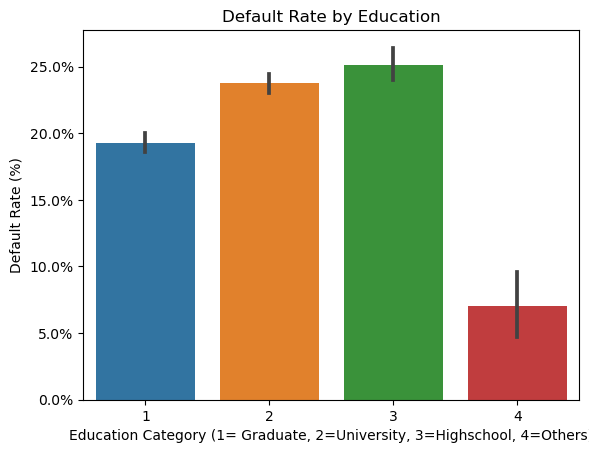

In [ ]:
#Calculating default rate by education
education_default = df.groupby("Education")["DEFAULT_NEXT_MONTH"].mean() * 100
print(education_default)

sns.barplot(x="Education", y="DEFAULT_NEXT_MONTH", data=df)

plt.title("Default Rate by Education")
plt.xlabel("Education Category (1= Graduate, 2=University, 3=Highschool, 4=Others)")
plt.ylabel("Default Rate (%)")
plt.gca().yaxis.set_major_formatter(PercentFormatter(1))
plt.show()

Marital_Status
1    23.471704
2    20.928339
3    23.607427
Name: DEFAULT_NEXT_MONTH, dtype: float64


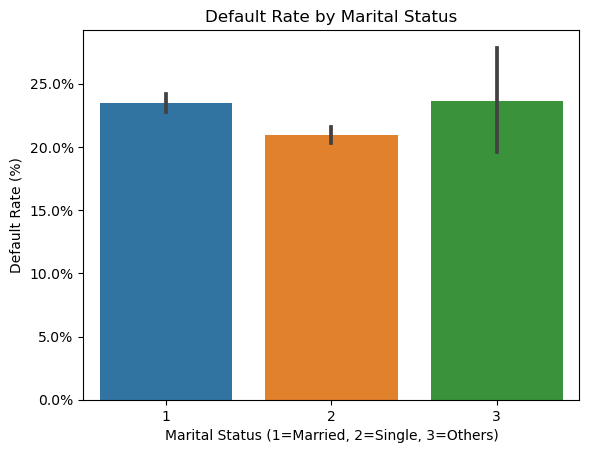

In [ ]:
#Calculating default rate by marital status
marital_default = df.groupby("Marital_Status")["DEFAULT_NEXT_MONTH"].mean() * 100
print(marital_default)

sns.barplot(x="Marital_Status", y="DEFAULT_NEXT_MONTH" ,data=df)

plt.title("Default Rate by Marital Status")
plt.xlabel("Marital Status (1=Married, 2=Single, 3=Others)")
plt.ylabel("Default Rate (%)")
plt.gca().yaxis.set_major_formatter(PercentFormatter(1))
plt.show()

REPAY_SEPTEMBER
-2    13.229431
-1    16.778051
 0    12.811291
 1    33.947939
 2    69.141357
 3    75.776398
 4    68.421053
 5    50.000000
 6    54.545455
 7    77.777778
 8    57.894737
Name: DEFAULT_NEXT_MONTH, dtype: float64


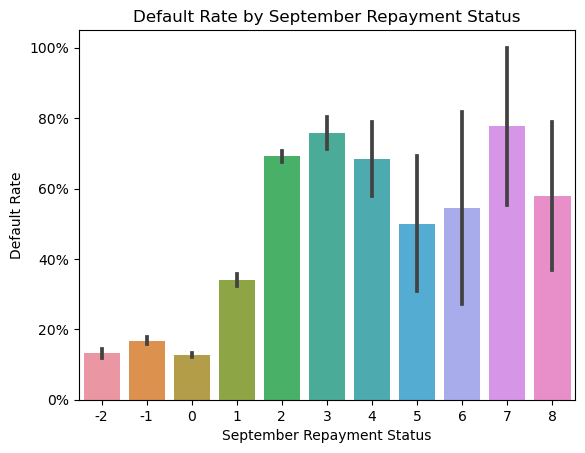

In [ ]:
#Showing the repayment status of customer over six month
repayment_columns = [
    "REPAY_SEPTEMBER",
    "REPAY_AUGUST",
    "REPAY_JULY",
    "REPAY_JUNE",
    "REPAY_MAY",
    "REPAY_APRIL"
]
repayment_default = df.groupby("REPAY_SEPTEMBER")["DEFAULT_NEXT_MONTH"].mean() * 100
print(repayment_default)

sns.barplot(
    x="REPAY_SEPTEMBER",
    y="DEFAULT_NEXT_MONTH",
    data=df
)
plt.title("Default Rate by September Repayment Status")
plt.xlabel("September Repayment Status")
plt.ylabel("Default Rate")
plt.gca().yaxis.set_major_formatter(PercentFormatter(1))
plt.show()

In [ ]:
# To calculate the default rate category by month. This is to know the repayment status of each category by month in percent
for col in repayment_columns:
    print(f"\nDefault rate by {col}:")
    print(df.groupby(col)["DEFAULT_NEXT_MONTH"].mean()*100)


Default rate by REPAY_SEPTEMBER:
REPAY_SEPTEMBER
-2    13.229431
-1    16.778051
 0    12.811291
 1    33.947939
 2    69.141357
 3    75.776398
 4    68.421053
 5    50.000000
 6    54.545455
 7    77.777778
 8    57.894737
Name: DEFAULT_NEXT_MONTH, dtype: float64

Default rate by REPAY_AUGUST:
REPAY_AUGUST
-2    18.270756
-1    15.966942
 0    15.912270
 1    17.857143
 2    55.614973
 3    61.656442
 4    50.505051
 5    60.000000
 6    75.000000
 7    60.000000
 8     0.000000
Name: DEFAULT_NEXT_MONTH, dtype: float64

Default rate by REPAY_JULY:
REPAY_JULY
-2    18.531212
-1    15.594476
 0    17.451155
 1    25.000000
 2    51.557999
 3    57.500000
 4    57.894737
 5    57.142857
 6    60.869565
 7    81.481481
 8    66.666667
Name: DEFAULT_NEXT_MONTH, dtype: float64

Default rate by REPAY_JUNE:
REPAY_JUNE
-2    19.250230
-1    15.895903
 0    18.328775
 1    50.000000
 2    52.326686
 3    61.111111
 4    66.666667
 5    51.428571
 6    40.000000
 7    82.758621
 8    50.000000

In [ ]:
# This is the count of customer repayment category by month
for col in repayment_columns:
    print(f"\nCustomer count by {col}:")
    print(df[col].value_counts().sort_index())


Customer count by REPAY_SEPTEMBER:
-2     2759
-1     5686
 0    14737
 1     3688
 2     2667
 3      322
 4       76
 5       26
 6       11
 7        9
 8       19
Name: REPAY_SEPTEMBER, dtype: int64

Customer count by REPAY_AUGUST:
-2     3782
-1     6050
 0    15730
 1       28
 2     3927
 3      326
 4       99
 5       25
 6       12
 7       20
 8        1
Name: REPAY_AUGUST, dtype: int64

Customer count by REPAY_JULY:
-2     4085
-1     5938
 0    15764
 1        4
 2     3819
 3      240
 4       76
 5       21
 6       23
 7       27
 8        3
Name: REPAY_JULY, dtype: int64

Customer count by REPAY_JUNE:
-2     4348
-1     5687
 0    16455
 1        2
 2     3159
 3      180
 4       69
 5       35
 6        5
 7       58
 8        2
Name: REPAY_JUNE, dtype: int64

Customer count by REPAY_MAY:
-2     4546
-1     5539
 0    16947
 2     2626
 3      178
 4       84
 5       17
 6        4
 7       58
 8        1
Name: REPAY_MAY, dtype: int64

Customer count by REPAY_APRIL

In [ ]:
# To calculate the  average bill statement by default payment in each month
bill_columns = [
    "BILL_SEPTEMBER",
    "BILL_AUGUST",
    "BILL_JULY",
    "BILL_JUNE",
    "BILL_MAY",
    "BILL_APRIL"
]
for col in bill_columns:
    print(f"\nAverage {col} by default status:")
    print(df.groupby("DEFAULT_NEXT_MONTH")[col].mean())


Average BILL_SEPTEMBER by default status:
DEFAULT_NEXT_MONTH
0    51994.227273
1    48509.162297
Name: BILL_SEPTEMBER, dtype: float64

Average BILL_AUGUST by default status:
DEFAULT_NEXT_MONTH
0    49717.435670
1    47283.617842
Name: BILL_AUGUST, dtype: float64

Average BILL_JULY by default status:
DEFAULT_NEXT_MONTH
0    47533.365605
1    45181.598855
Name: BILL_JULY, dtype: float64

Average BILL_JUNE by default status:
DEFAULT_NEXT_MONTH
0    43611.165254
1    42036.950573
Name: BILL_JUNE, dtype: float64

Average BILL_MAY by default status:
DEFAULT_NEXT_MONTH
0    40530.445343
1    39540.190476
Name: BILL_MAY, dtype: float64

Average BILL_APRIL by default status:
DEFAULT_NEXT_MONTH
0    39042.268704
1    38271.435503
Name: BILL_APRIL, dtype: float64


In [ ]:
payment_columns = [
    "PAYMENT_SEPTEMBER",
    "PAYMENT_AUGUST",
    "PAYMENT_JULY",
    "PAYMENT_JUNE",
    "PAYMENT_MAY",
    "PAYMENT_APRIL"
]

for col in payment_columns:
    print(f"\nAverage {col} by default status:")
    print(df.groupby("DEFAULT_NEXT_MONTH")[col].mean())


Average PAYMENT_SEPTEMBER by default status:
DEFAULT_NEXT_MONTH
0    6307.337357
1    3397.044153
Name: PAYMENT_SEPTEMBER, dtype: float64

Average PAYMENT_AUGUST by default status:
DEFAULT_NEXT_MONTH
0    6640.465074
1    3388.649638
Name: PAYMENT_AUGUST, dtype: float64

Average PAYMENT_JULY by default status:
DEFAULT_NEXT_MONTH
0    5753.496833
1    3367.351567
Name: PAYMENT_JULY, dtype: float64

Average PAYMENT_JUNE by default status:
DEFAULT_NEXT_MONTH
0    5300.529319
1    3155.626733
Name: PAYMENT_JUNE, dtype: float64

Average PAYMENT_MAY by default status:
DEFAULT_NEXT_MONTH
0    5248.220296
1    3219.139542
Name: PAYMENT_MAY, dtype: float64

Average PAYMENT_APRIL by default status:
DEFAULT_NEXT_MONTH
0    5719.371769
1    3441.482068
Name: PAYMENT_APRIL, dtype: float64


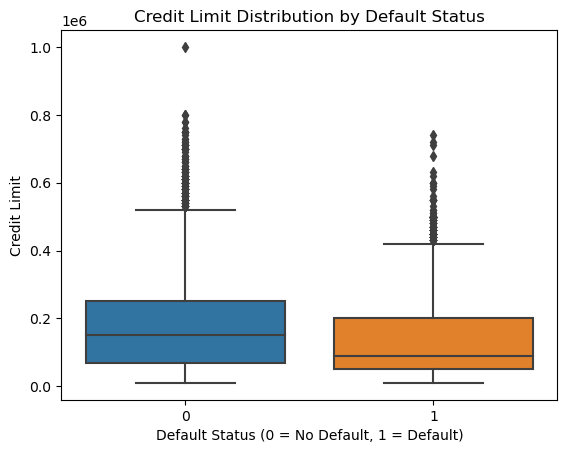

In [ ]:
df.groupby("DEFAULT_NEXT_MONTH")["Credit_Limit"].mean()

sns.boxplot(x="DEFAULT_NEXT_MONTH", y="Credit_Limit", data=df)

plt.title("Credit Limit Distribution by Default Status")
plt.xlabel("Default Status (0 = No Default, 1 = Default)")
plt.ylabel("Credit Limit")
plt.show()

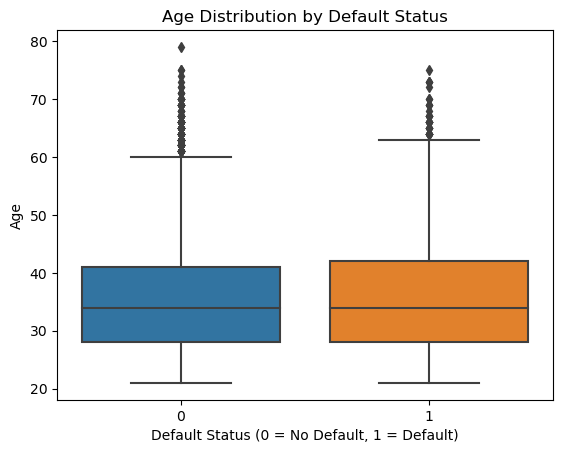

In [ ]:
sns.boxplot(x="DEFAULT_NEXT_MONTH", y="Age", data=df)

plt.title("Age Distribution by Default Status")
plt.xlabel("Default Status (0 = No Default, 1 = Default)")
plt.ylabel("Age")
plt.show()

In [ ]:
X = df.drop(columns=["Customer_ID", "DEFAULT_NEXT_MONTH"])

y = df["DEFAULT_NEXT_MONTH"]

In [ ]:
print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (30000, 23)
Target shape: (30000,)


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.3,
    random_state=42,
    stratify=y
)
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)


Training features: (21000, 23)
Testing features: (9000, 23)
Training target: (21000,)
Testing target: (9000,)


In [ ]:
categorical_features = [
    "Gender",
    "Education",
    "Marital_Status"
]

numerical_features = [
    col for col in X.columns
    if col not in categorical_features
]

In [ ]:
preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features),
        ("numerical", StandardScaler(), numerical_features)
    ]
)

model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ))
])

model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('categorical',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Gender', 'Education',
                                                   'Marital_Status']),
                                                 ('numerical', StandardScaler(),
                                                  ['Credit_Limit', 'Age',
                                                   'REPAY_SEPTEMBER',
                                                   'REPAY_AUGUST', 'REPAY_JULY',
                                                   'REPAY_JUNE', 'REPAY_MAY',
                                                   'REPAY_APRIL',
                                                   'BILL_SEPTEMBER',
                                                   'BILL_AUGUST', 'BILL_JULY',
                                                   'BILL_JUNE', 'BILL_MAY',
                                                   'BILL_APRIL',
                                                   'PAYMENT_SEPTEMBER',
                                                   'PAYMENT_AUGUST',
                                                   'PAYMENT_JULY',
                                                   'PAYMENT_JUNE',
                                                   'PAYMENT_MAY',
                                                   'PAYMENT_APRIL'])])),
                ('classifier',
                 LogisticRegression(class_weight='balanced', max_iter=1000))])

In [ ]:
y_pred = model.predict(X_test)

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy)

print(classification_report(y_test, y_pred))

Model Accuracy: 0.6823333333333333
              precision    recall  f1-score   support

           0       0.87      0.69      0.77      7009
           1       0.37      0.64      0.47      1991

    accuracy                           0.68      9000
   macro avg       0.62      0.67      0.62      9000
weighted avg       0.76      0.68      0.71      9000



In [ ]:
cm = confusion_matrix(y_test, y_pred)

print(cm)

[[4870 2139]
 [ 720 1271]]


In [ ]:
rf_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('categorical',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Gender', 'Education',
                                                   'Marital_Status']),
                                                 ('numerical', StandardScaler(),
                                                  ['Credit_Limit', 'Age',
                                                   'REPAY_SEPTEMBER',
                                                   'REPAY_AUGUST', 'REPAY_JULY',
                                                   'REPAY_JUNE', 'REPAY_MAY',
                                                   'REPAY_APRIL',
                                                   'BILL_SEPTEMBER',
                                                   'BILL_AUGUST', 'BILL_JULY',
                                                   'BILL_JUNE', 'BILL_MAY',
                                                   'BILL_APRIL',
                                                   'PAYMENT_SEPTEMBER',
                                                   'PAYMENT_AUGUST',
                                                   'PAYMENT_JULY',
                                                   'PAYMENT_JUNE',
                                                   'PAYMENT_MAY',
                                                   'PAYMENT_APRIL'])])),
                ('classifier',
                 RandomForestClassifier(class_weight='balanced', n_jobs=-1,
                                        random_state=42))])

In [ ]:
rf_pred = rf_model.predict(X_test)

In [ ]:
from sklearn.metrics import accuracy_score

rf_accuracy = accuracy_score(y_test, rf_pred)

print("Random Forest Accuracy:", rf_accuracy)

from sklearn.metrics import classification_report

print(classification_report(y_test, rf_pred))

Random Forest Accuracy: 0.8134444444444444
              precision    recall  f1-score   support

           0       0.84      0.95      0.89      7009
           1       0.65      0.34      0.45      1991

    accuracy                           0.81      9000
   macro avg       0.74      0.65      0.67      9000
weighted avg       0.79      0.81      0.79      9000



[[6636  373]
 [1306  685]]


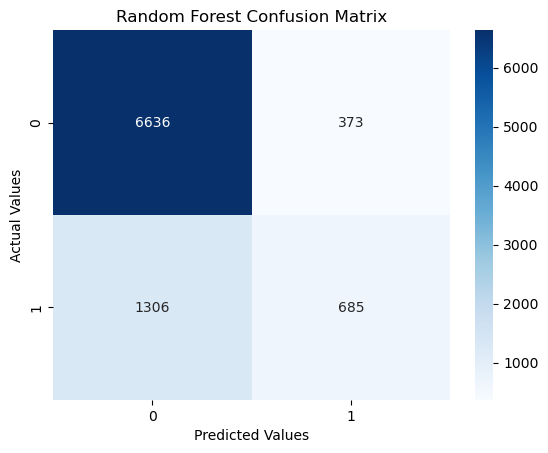

In [ ]:
from sklearn.metrics import confusion_matrix

rf_cm = confusion_matrix(y_test, rf_pred)

print(rf_cm)

sns.heatmap(rf_cm, annot=True, fmt="d", cmap="Blues")

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")
plt.show()

In [ ]:
from sklearn.metrics import roc_auc_score

# Logistic Regression
lr_prob = model.predict_proba(X_test)[:, 1]

lr_auc = roc_auc_score(y_test, lr_prob)

print("Logistic Regression AUC:", lr_auc)


# Random Forest
rf_prob = rf_model.predict_proba(X_test)[:, 1]

rf_auc = roc_auc_score(y_test, rf_prob)

print("Random Forest AUC:", rf_auc)

Logistic Regression AUC: 0.7172403150458989
Random Forest AUC: 0.7584898916288945


In [ ]:
from sklearn.metrics import precision_recall_curve
import numpy as np

# Logistic Regression
lr_precision, lr_recall, lr_thresholds = precision_recall_curve(
    y_test, lr_prob
)

lr_f1 = (
    2 * lr_precision[:-1] * lr_recall[:-1] /
    (lr_precision[:-1] + lr_recall[:-1] + 1e-10)
)

lr_best_index = np.argmax(lr_f1)

print("Logistic Regression best threshold:",
      lr_thresholds[lr_best_index])
print("Best F1-score:", lr_f1[lr_best_index])


# Random Forest
rf_precision, rf_recall, rf_thresholds = precision_recall_curve(
    y_test, rf_prob
)

rf_f1 = (
    2 * rf_precision[:-1] * rf_recall[:-1] /
    (rf_precision[:-1] + rf_recall[:-1] + 1e-10)
)

rf_best_index = np.argmax(rf_f1)

print("Random Forest best threshold:",
      rf_thresholds[rf_best_index])
print("Best F1-score:", rf_f1[rf_best_index])

Logistic Regression best threshold: 0.5622666276053431
Best F1-score: 0.5059089765655393
Random Forest best threshold: 0.29
Best F1-score: 0.5289335245794783
